# heatwaves_monthly_CESM2.ipynb
## Calculate marine heatwaves with CESM2 using the 90th (and 10th) percentile of monthly data.

#### Created by Brendan Myers
##### 09/02/2026

In [1]:
%load_ext autoreload
%autoreload 2
import os
from glob import glob
from collections import OrderedDict
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs
import pop_tools 
from statistics import mean
from matplotlib import style
import colorcet as cc
from scipy import stats

import xmhw

ERROR 1: PROJ: proj_create_from_database: Open of /glade/work/brendanmy/conda-envs/bgc-env/share/proj failed
/glade/work/brendanmy/conda-envs/bgc-env/lib/python3.13/site-packages/pop_tools/__init__.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


## Create Dask Cluster

In [2]:
try:
    client.shutdown()
except:
    pass

In [3]:
import dask
from DaskSetup import DaskSetup

try:
    client.shutdown()
except:
    pass

dask.config.set({'logging.distributed': 'error'})

cluster, client = DaskSetup.get_ClusterClient(memory='25GB', walltime='03:00:00', account='P93300070')
# cluster.scale(12) 
cluster.adapt(minimum_jobs=10, maximum_jobs=30)
print(cluster.job_script())
# client

#!/usr/bin/env bash

#PBS -N dask-worker
#PBS -q casper
#PBS -A P93300070
#PBS -l select=1:ncpus=1:mem=25GB
#PBS -l walltime=03:00:00
#PBS -e /glade/derecho/scratch/brendanmy/dask_logs//
#PBS -o /glade/derecho/scratch/brendanmy/dask_logs//

/glade/work/brendanmy/conda-envs/bgc-env/bin/python -m distributed.cli.dask_worker tcp://128.117.208.173:42131 --name dummy-name --nthreads 2 --memory-limit 23.28GiB --nanny --death-timeout 60 --local-directory /glade/derecho/scratch/brendanmy/dask_logs/ --interface ext



In [4]:
client.wait_for_workers(1)
client

<Client: 'tcp://128.117.208.173:42131' processes=0 threads=0, memory=0 B>

# Open Data

### Get grid info: we need a land/ocean mask, lats, lons, and major basin masks

In [5]:
### First, get the pop grid information, so we have lon, lat
ds_grid = pop_tools.get_grid('POP_gx1v7')
lats = ds_grid.TLAT
lons = ds_grid.TLONG

In [6]:
### Second, create an empty ones array on the model grid
ones = np.full((384,320),1,dtype=int)
ones = xr.DataArray(ones,dims=('nlat','nlon'))

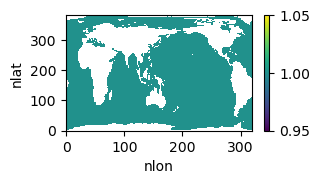

In [7]:
### third, use the REGION_MASK variable and the ones array to create a land mask
ones = ones.where(ds_grid.REGION_MASK>0)
ones.plot(figsize=(3,1.5))

In [8]:
### forth, get the major basins mask 
major_basins = xr.open_dataset('/glade/work/kristenk/ocean_masks/major_basins.nc')

major_basins = major_basins.basin.values
major_basins = xr.DataArray(major_basins, dims=('nlat','nlon'))

### Get the model FOSI run

In [9]:
case = 'g.e22.GOMIPECOIAF_JRA-1p4-2018.TL319_g17.4p2z.002branch'
path = '/glade/campaign/cesm/development/bgcwg/projects/CESM2-OMIP2-like-4p2z-run/'+case+'/ocn/proc/tseries/month_1/'

In [10]:
# variables = ['IFRAC','HMXL','diatChl','spChl','coccoChl','diazChl','TEMP']
variables = ['TEMP']

In [11]:
def preprocess(ds):
    ds = ds.isel(z_t=0)
    ds = ds.isel(z_t_150m=0)
    return ds

In [12]:
ds_fosi = xr.Dataset()

for var in variables:
    
    print('starting on ', var)
    ################ FOSI
    
    #ds_tmp = xr.open_dataset(path+case+'.pop.h.'+var+'.??????-??????.nc')
    #ds_tmp['time'] = time
    
    files = sorted(glob(f'{path}/{case}.pop.h.{var}.??????-??????.nc'))       
    ds_tmp = xr.open_mfdataset(files, data_vars="minimal", coords='minimal', compat="override", parallel=True, concat_dim="time",
                       drop_variables=["transport_components", "transport_regions"], decode_times=True, preprocess=preprocess, combine='nested')

    keep_vars=['z_t','z_t_150m','time_bound','dz','TLAT','TLONG','time','KMT'] + [var]

    ds_tmp = ds_tmp.drop_vars([v for v in ds_tmp.variables if v not in keep_vars])
        
    ds_fosi = xr.merge([ds_fosi,ds_tmp], compat='override')

starting on  TEMP


### Make a mean of the time bounds (CESM-specific)

In [13]:
ds_fosi["time"] = ds_fosi.time_bound.compute().mean(dim="d2")

### trim to the satellite period since 2003

In [14]:
ds_fosi.time[540:768]

<xarray.DataArray 'time' (time: 228)> Size: 2kB
array([cftime.DatetimeNoLeap(2003, 1, 16, 12, 0, 0, 0, has_year_zero=True),
       cftime.DatetimeNoLeap(2003, 2, 15, 0, 0, 0, 0, has_year_zero=True),
       cftime.DatetimeNoLeap(2003, 3, 16, 12, 0, 0, 0, has_year_zero=True),
       ...,
       cftime.DatetimeNoLeap(2021, 10, 16, 12, 0, 0, 0, has_year_zero=True),
       cftime.DatetimeNoLeap(2021, 11, 16, 0, 0, 0, 0, has_year_zero=True),
       cftime.DatetimeNoLeap(2021, 12, 16, 12, 0, 0, 0, has_year_zero=True)],
      shape=(228,), dtype=object)
Coordinates:
  * time      (time) object 2kB 2003-01-16 12:00:00 ... 2021-12-16 12:00:00
    z_t       float32 4B 500.0
    z_t_150m  float32 4B 500.0
Attributes:
    long_name:     boundaries for time-averaging interval
    cell_methods:  time: mean

In [15]:
### slice the data
ds_fosi = ds_fosi.isel(time=slice(540,768))

In [16]:
ds_fosi.load()

<xarray.Dataset> Size: 115MB
Dimensions:     (nlat: 384, nlon: 320, time: 228, d2: 2)
Coordinates:
  * time        (time) object 2kB 2003-01-16 12:00:00 ... 2021-12-16 12:00:00
    TLAT        (nlat, nlon) float64 983kB -79.22 -79.22 -79.22 ... nan nan nan
    TLONG       (nlat, nlon) float64 983kB 320.6 321.7 322.8 ... nan nan nan
    z_t         float32 4B 500.0
    z_t_150m    float32 4B 500.0
Dimensions without coordinates: nlat, nlon, d2
Data variables:
    KMT         (nlat, nlon) float64 983kB 0.0 0.0 0.0 0.0 ... nan nan nan nan
    TEMP        (time, nlat, nlon) float32 112MB nan nan nan nan ... nan nan nan
    dz          float32 4B 1e+03
    time_bound  (time, d2) object 4kB 2003-01-01 00:00:00 ... 2022-01-01 00:0...

In [17]:
import psutil
import os

# Get current process memory usage in MB
process = psutil.Process(os.getpid())
mem_info = process.memory_info()
print(f"Memory usage: {mem_info.rss / 1024 ** 3:.2f} GB")


Memory usage: 0.73 GB


# A few precalculations....

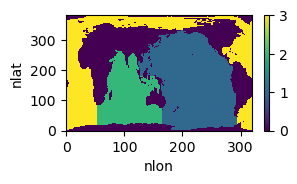

In [18]:
major_basins.plot(figsize=(3,1.5))

### Assign basins

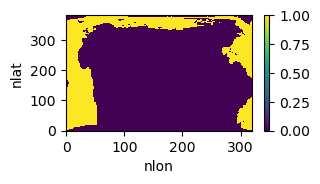

In [19]:
Atlantic = ones.where(major_basins == 3, other=0)
#.where(major_basins.basin == 3) #ones.where(ds_grid.REGION_MASK >= 5, other=0).where(ds_grid.REGION_MASK<10, other=0)
Atlantic.plot(figsize=(3,1.5))

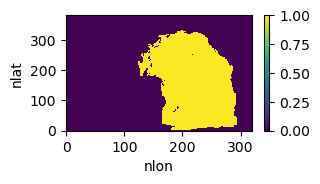

In [20]:
Pacific = ones.where(major_basins == 1, other=0)
Pacific.plot(figsize=(3,1.5))

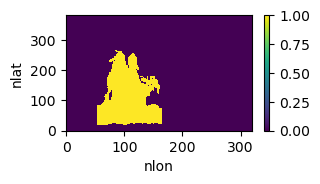

In [21]:
Indian = ones.where(major_basins == 2, other=0)
Indian.plot(figsize=(3,1.5))

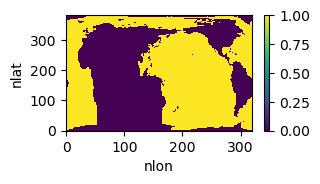

In [22]:
Atlantic_Pacific = Atlantic + Pacific
Atlantic_Pacific.plot(figsize=(3,1.5))

In [23]:
ds_fosi['basin_mask'] = major_basins
ds_fosi

<xarray.Dataset> Size: 116MB
Dimensions:     (nlat: 384, nlon: 320, time: 228, d2: 2)
Coordinates:
  * time        (time) object 2kB 2003-01-16 12:00:00 ... 2021-12-16 12:00:00
    TLAT        (nlat, nlon) float64 983kB -79.22 -79.22 -79.22 ... nan nan nan
    TLONG       (nlat, nlon) float64 983kB 320.6 321.7 322.8 ... nan nan nan
    z_t         float32 4B 500.0
    z_t_150m    float32 4B 500.0
Dimensions without coordinates: nlat, nlon, d2
Data variables:
    KMT         (nlat, nlon) float64 983kB 0.0 0.0 0.0 0.0 ... nan nan nan nan
    TEMP        (time, nlat, nlon) float32 112MB nan nan nan nan ... nan nan nan
    dz          float32 4B 1e+03
    time_bound  (time, d2) object 4kB 2003-01-01 00:00:00 ... 2022-01-01 00:0...
    basin_mask  (nlat, nlon) float64 983kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0

In [24]:
ds_fosi['TEMP_anom'] = ds_fosi['TEMP'].groupby('time.month') - ds_fosi['TEMP'].groupby('time.month').mean(dim='time')
ds_fosi['TEMP_anom'].attrs = ds_fosi['TEMP_anom'].attrs | {'long_name': 'Potential Temperature Anomoly'}

# Calc Heatwaves

In [25]:
import pandas as pd
from matplotlib.colors import BoundaryNorm
import matplotlib.colors as mcolors
from matplotlib.colors import LinearSegmentedColormap

def blue2red_cmap(n):
    """ combine two existing color maps to create a diverging color map with white in the middle
    n = the number of contour intervals
    """
    if (int(n/2) == n/2):
        # even number of contours
        nwhite=1
        nhalf=n//2
    else:
        nwhite=2
        nhalf = (n-1)//2

    #making mpl colormap from ncl colortable
    cmap_name='nrl_sirkes'
    colortab=pd.read_csv('https://www.ncl.ucar.edu/Document/Graphics/ColorTables/Files/'+cmap_name+'.rgb',sep='\\s+')
    cmap = LinearSegmentedColormap.from_list(cmap_name, colortab.values/255, N=(nhalf*2))

    colorsall = cmap(np.linspace(0,1, nhalf*2))
    
    colors1 = colorsall[:nhalf]
    colors2 = colorsall[nhalf:]
    colorsw = np.ones((nwhite,4))
    colors = np.vstack((colors1, colorsw, colors2))
    cmap = mcolors.LinearSegmentedColormap.from_list('my_colormap', colors)
    return cmap

In [26]:
# cmap_div = cc.cm.coolwarm
levs = np.arange(-4, 4.05, .05)
cmap_div = blue2red_cmap(len(levs))
cmap_div.set_over("grey")  # Color for data above vmax
cmap_div.set_under("grey")


norm = BoundaryNorm(levs, ncolors=cmap_div.N, clip=False)

## Monthly

In [27]:
# Need groupby to do this by month
quantile_upp_mon = ds_fosi.TEMP_anom.groupby('time.month').quantile(0.9, dim='time', skipna=True)
quantile_low_mon = ds_fosi.TEMP_anom.groupby('time.month').quantile(0.1, dim='time', skipna=True)


tmp_g = ds_fosi.groupby('time.month')

mon_sep_list_mhw = []
mon_sep_list_mcw = []
for i, mon in enumerate(range(1,13)):
    tmp = tmp_g[mon]
    mon_sep_list_mhw.append(tmp.TEMP_anom.where((tmp.TEMP_anom>=quantile_upp_mon[i]) | (ds_fosi.TEMP_anom.isnull()), other=-9999).drop_vars(['month']))
    mon_sep_list_mcw.append(tmp.TEMP_anom.where((tmp.TEMP_anom<=quantile_low_mon[i]) | (ds_fosi.TEMP_anom.isnull()), other=-9999).drop_vars(['month']))

ds_fosi['MHW_monthly'] = xr.concat(mon_sep_list_mhw, dim='time', coords='minimal').sortby('time').rename('MHW_monthly')
ds_fosi['MHW_monthly'].attrs = ds_fosi['MHW_monthly'].attrs | {'quantile': quantile_upp_mon['quantile'].item()}
ds_fosi['MCW_monthly'] = xr.concat(mon_sep_list_mcw, dim='time', coords='minimal').sortby('time').rename('MCW_monthly')
ds_fosi['MCW_monthly'].attrs = ds_fosi['MCW_monthly'].attrs | {'quantile': quantile_low_mon['quantile'].item()}

ds_fosi = ds_fosi.drop_vars('quantile')

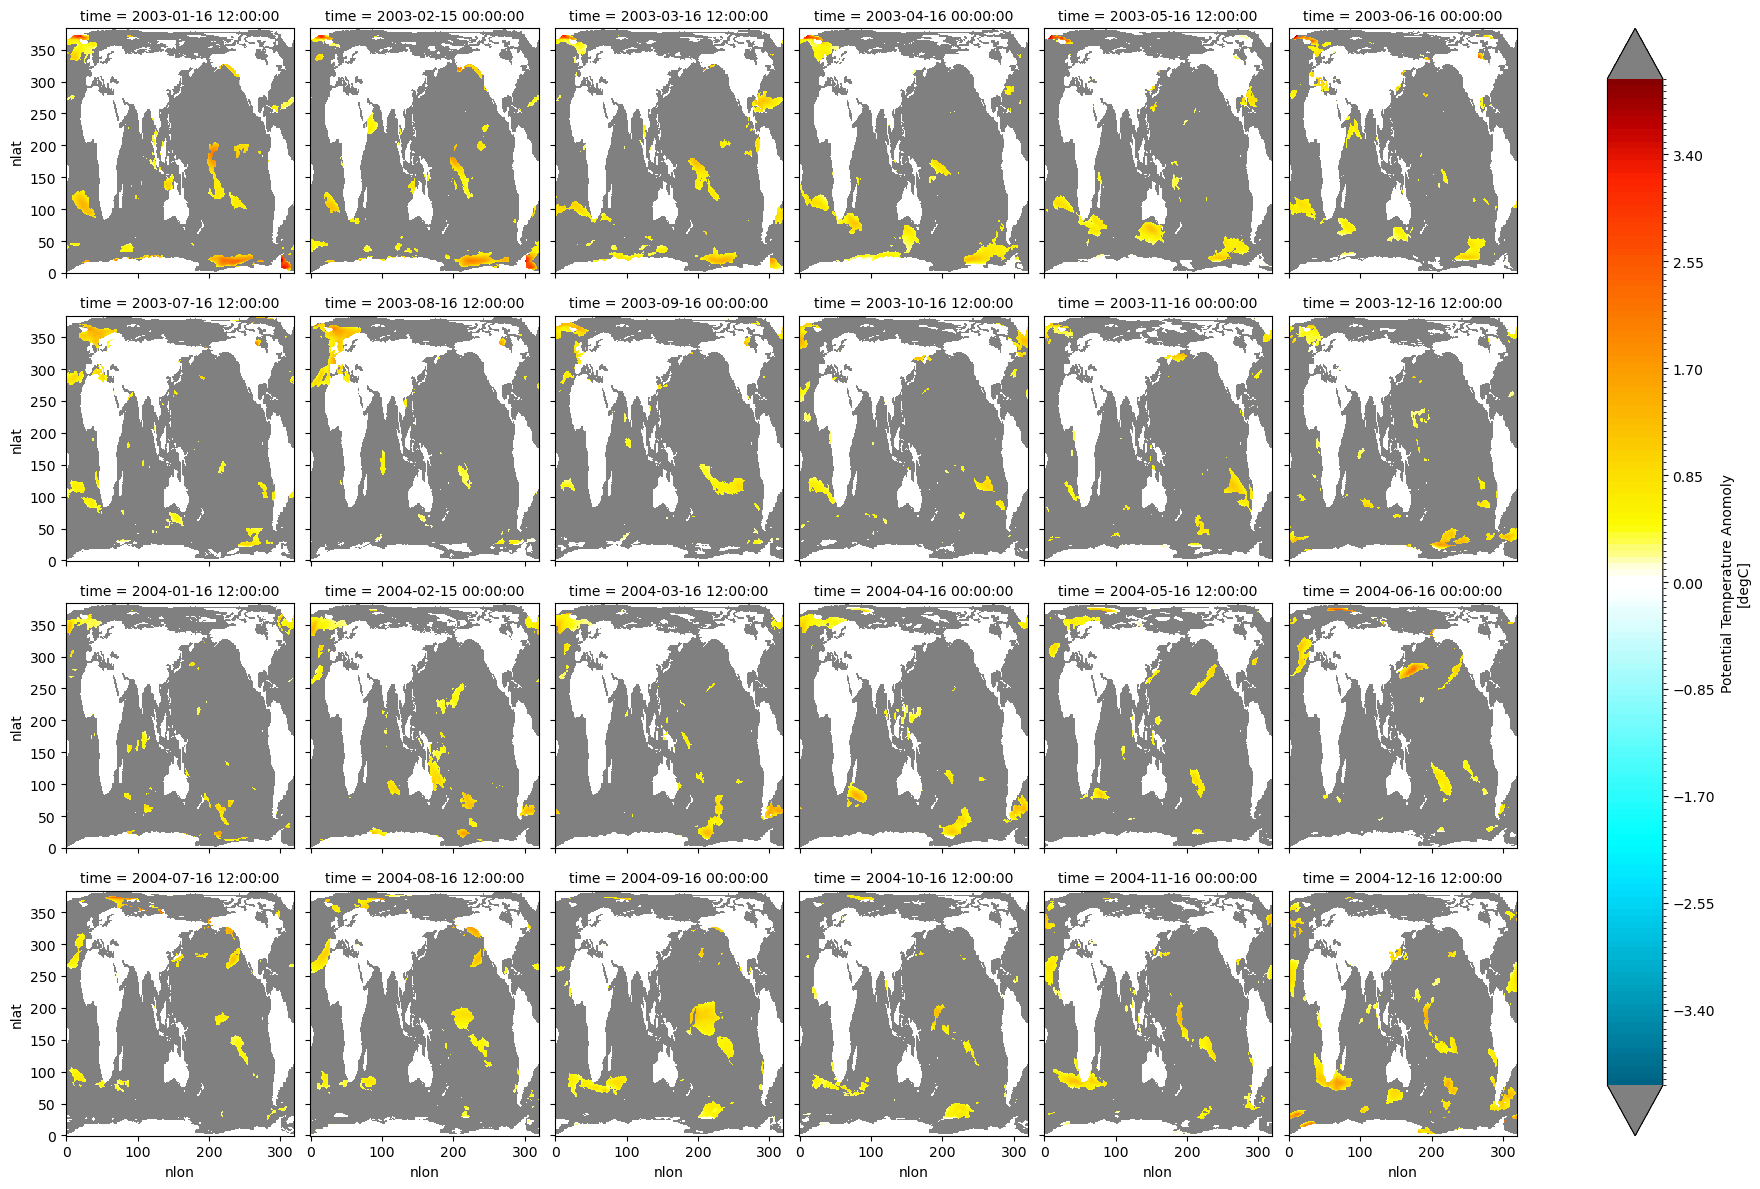

In [28]:
# Marine Heatwaves at Timesteps

ds_fosi.isel(time=slice(0,24)).MHW_monthly.plot(col='time', col_wrap=6, cmap=cmap_div, levels=levs, cbar_kwargs={'extend':'both'})

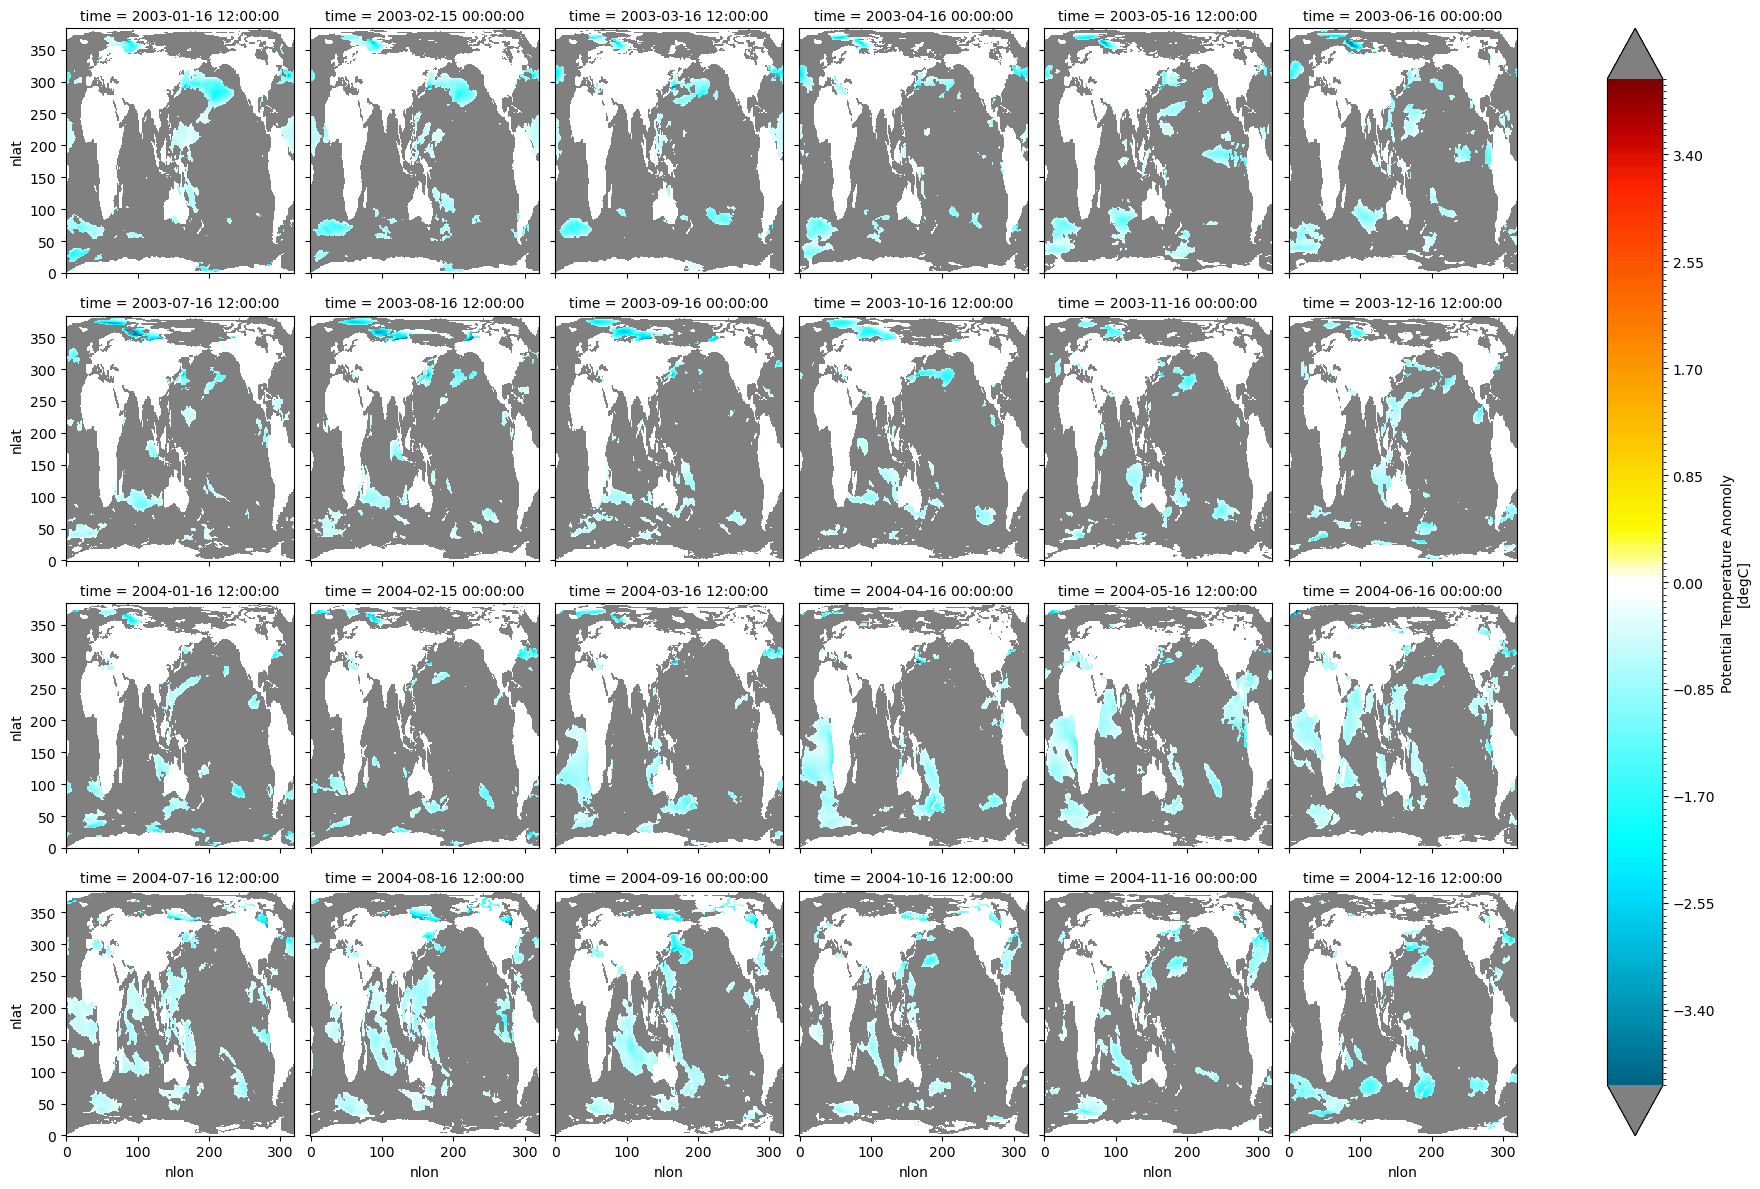

In [29]:
# Marine Coldwaves at Timesteps

ds_fosi.isel(time=slice(0,24)).MCW_monthly.plot(col='time', col_wrap=6, cmap=cmap_div, levels=levs, cbar_kwargs={'extend':'both'})

In [30]:
# Compute Intensity and Merge MHW and MCW together

ds_intensity_mon = xr.merge([ds_fosi.MHW_monthly.where(ds_fosi.MHW_monthly>-999, drop=False).groupby('time.month').mean('time').rename('MHW_INTENSITY'),ds_fosi.MCW_monthly.where(ds_fosi.MCW_monthly>-999, drop=False).groupby('time.month').mean('time').rename('MCW_INTENSITY')])

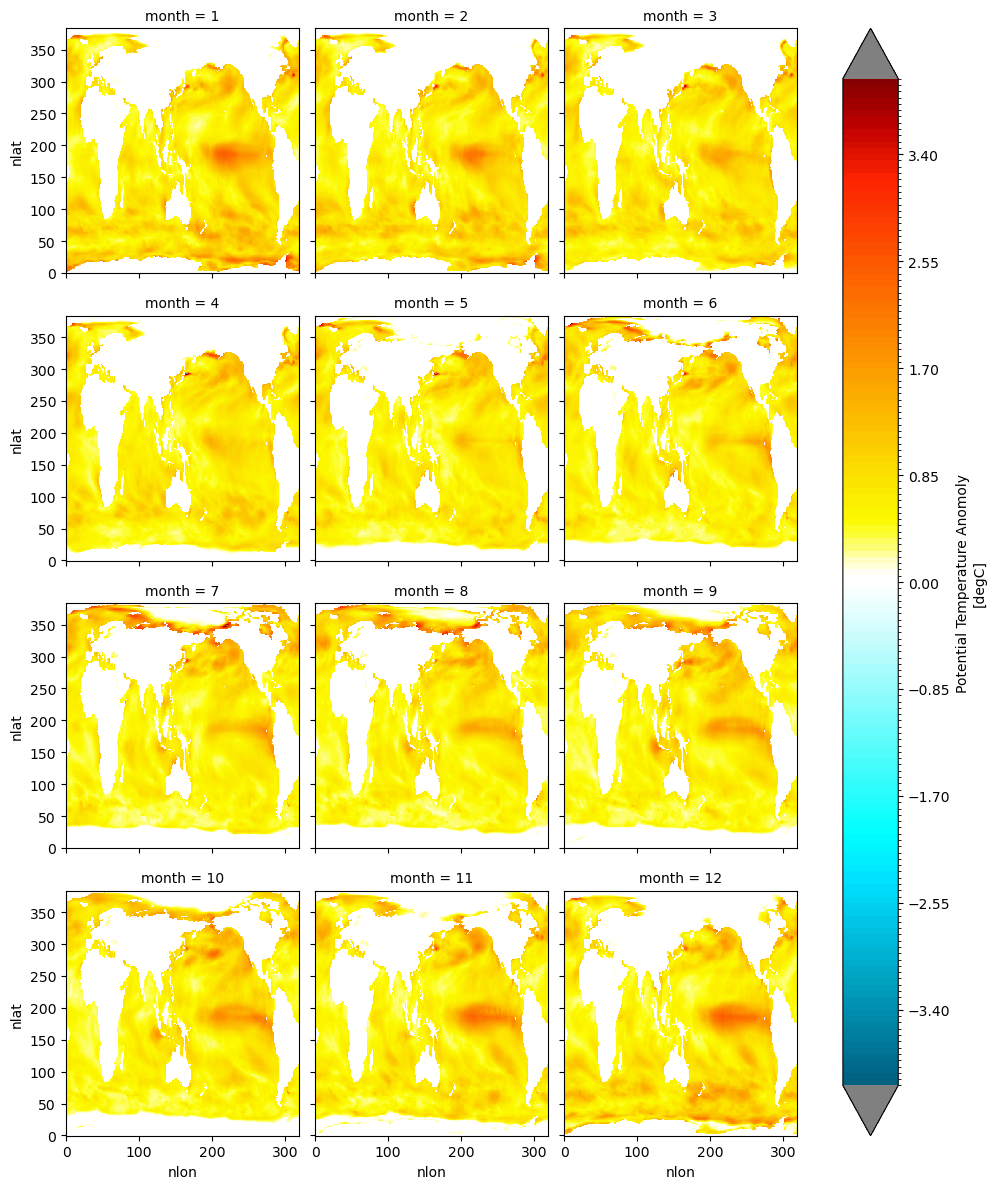

In [31]:
# Intensity of Marine Heatwaves

ds_intensity_mon['MHW_INTENSITY'].plot(col='month',col_wrap=3, cmap=cmap_div, levels=levs, cbar_kwargs={'extend':'both'})

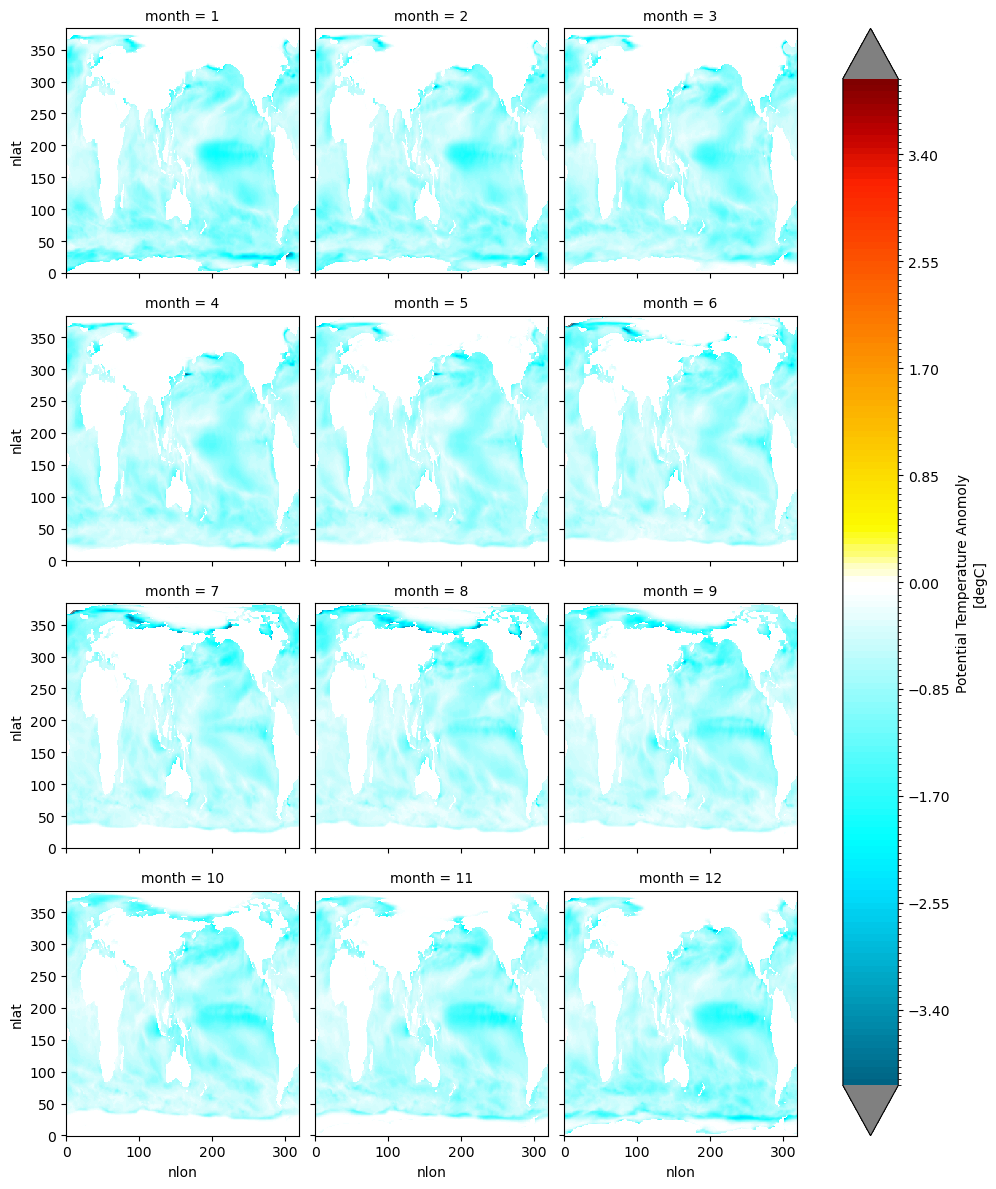

In [32]:
# Intensity of Marine Coldwaves

ds_intensity_mon['MCW_INTENSITY'].plot(col='month',col_wrap=3, cmap=cmap_div, levels=levs, cbar_kwargs={'extend':'both'})

## Annual

In [33]:
# Need groupby to do this by year
quantile_upp_ann = ds_fosi.TEMP_anom.groupby('time.year').quantile(0.9, dim='time', skipna=True)
quantile_low_ann = ds_fosi.TEMP_anom.groupby('time.year').quantile(0.1, dim='time', skipna=True)


tmp_g = ds_fosi.groupby('time.year')
yr_0 = min(list(tmp_g.groups.keys()))

mon_sep_list_mhw = []
mon_sep_list_mcw = []
for i, yr in enumerate(range(yr_0, yr_0+len(tmp_g.groups))):
    tmp = tmp_g[yr]
    mon_sep_list_mhw.append(tmp.TEMP_anom.where((tmp.TEMP_anom>=quantile_upp_ann[i]) | (ds_fosi.TEMP_anom.isnull()), other=-9999).drop_vars(['year']))
    mon_sep_list_mcw.append(tmp.TEMP_anom.where((tmp.TEMP_anom<=quantile_low_ann[i]) | (ds_fosi.TEMP_anom.isnull()), other=-9999).drop_vars(['year']))

ds_fosi['MHW_annual'] = xr.concat(mon_sep_list_mhw, dim='time', coords='minimal').sortby('time').rename('MHW_annual')
ds_fosi['MHW_annual'].attrs = ds_fosi['MHW_annual'].attrs | {'quantile': quantile_upp_ann['quantile'].item()}
ds_fosi['MCW_annual'] = xr.concat(mon_sep_list_mcw, dim='time', coords='minimal').sortby('time').rename('MCW_annual')
ds_fosi['MCW_annual'].attrs = ds_fosi['MCW_annual'].attrs | {'quantile': quantile_low_ann['quantile'].item()}

ds_fosi = ds_fosi.drop_vars('quantile')

In [34]:
ds_fosi.TEMP_anom.sel(nlat=200, nlon=200).groupby('time.year')[2011]

<xarray.DataArray 'TEMP_anom' (time: 12)> Size: 48B
array([-1.6682415 , -1.3437786 , -0.9466667 , -0.8035259 , -0.8378372 ,
       -0.8763485 , -0.7631836 , -0.7255554 , -0.74653435, -0.79842377,
       -0.8744068 , -1.045744  ], dtype=float32)
Coordinates:
  * time      (time) object 96B 2011-01-16 12:00:00 ... 2011-12-16 12:00:00
    TLAT      float64 8B 3.624
    TLONG     float64 8B 185.6
    z_t       float32 4B 500.0
    z_t_150m  float32 4B 500.0
    month     (time) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
Attributes:
    long_name:     Potential Temperature Anomoly
    units:         degC
    grid_loc:      3111
    cell_methods:  time: mean

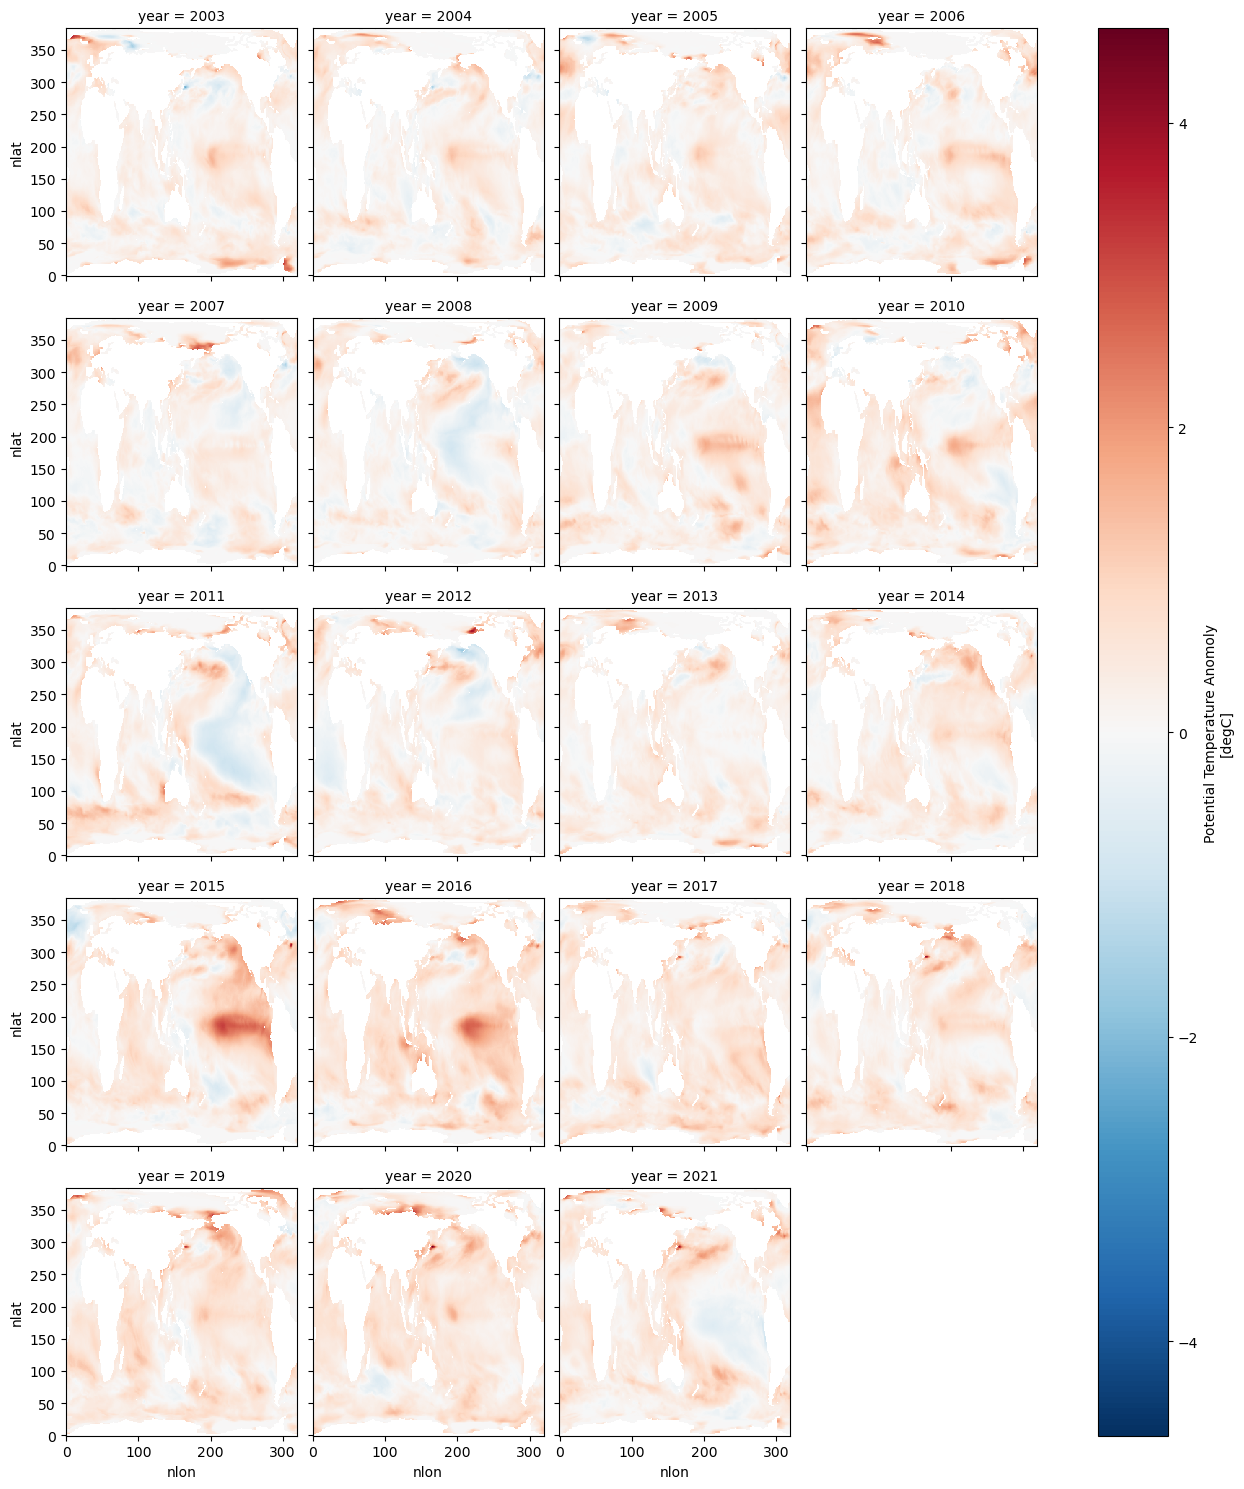

In [35]:
quantile_upp_ann.plot(col='year', col_wrap=4)

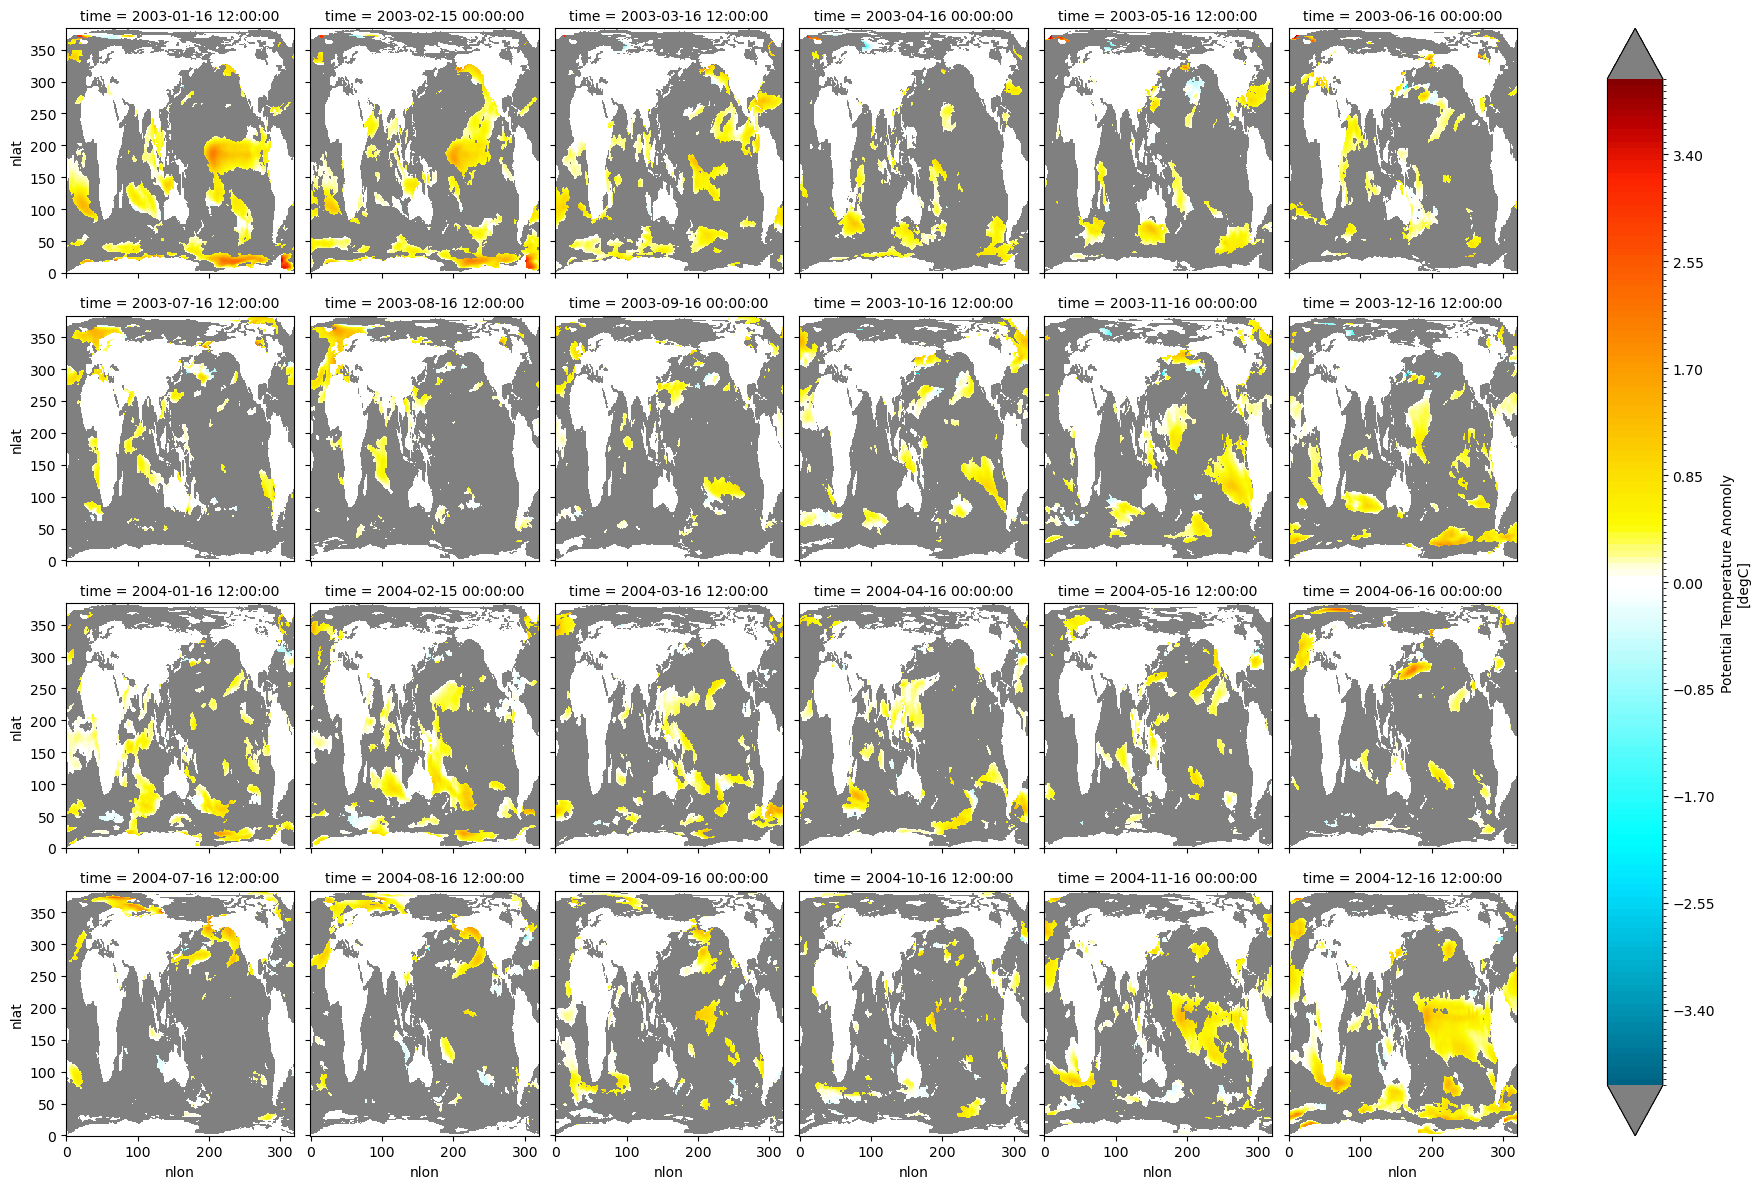

In [36]:
# Marine Heatwaves at Timesteps
ds_fosi.isel(time=slice(0,24)).MHW_annual.plot(col='time', col_wrap=6, cmap=cmap_div, levels=levs, cbar_kwargs={'extend':'both', 'norm':norm})

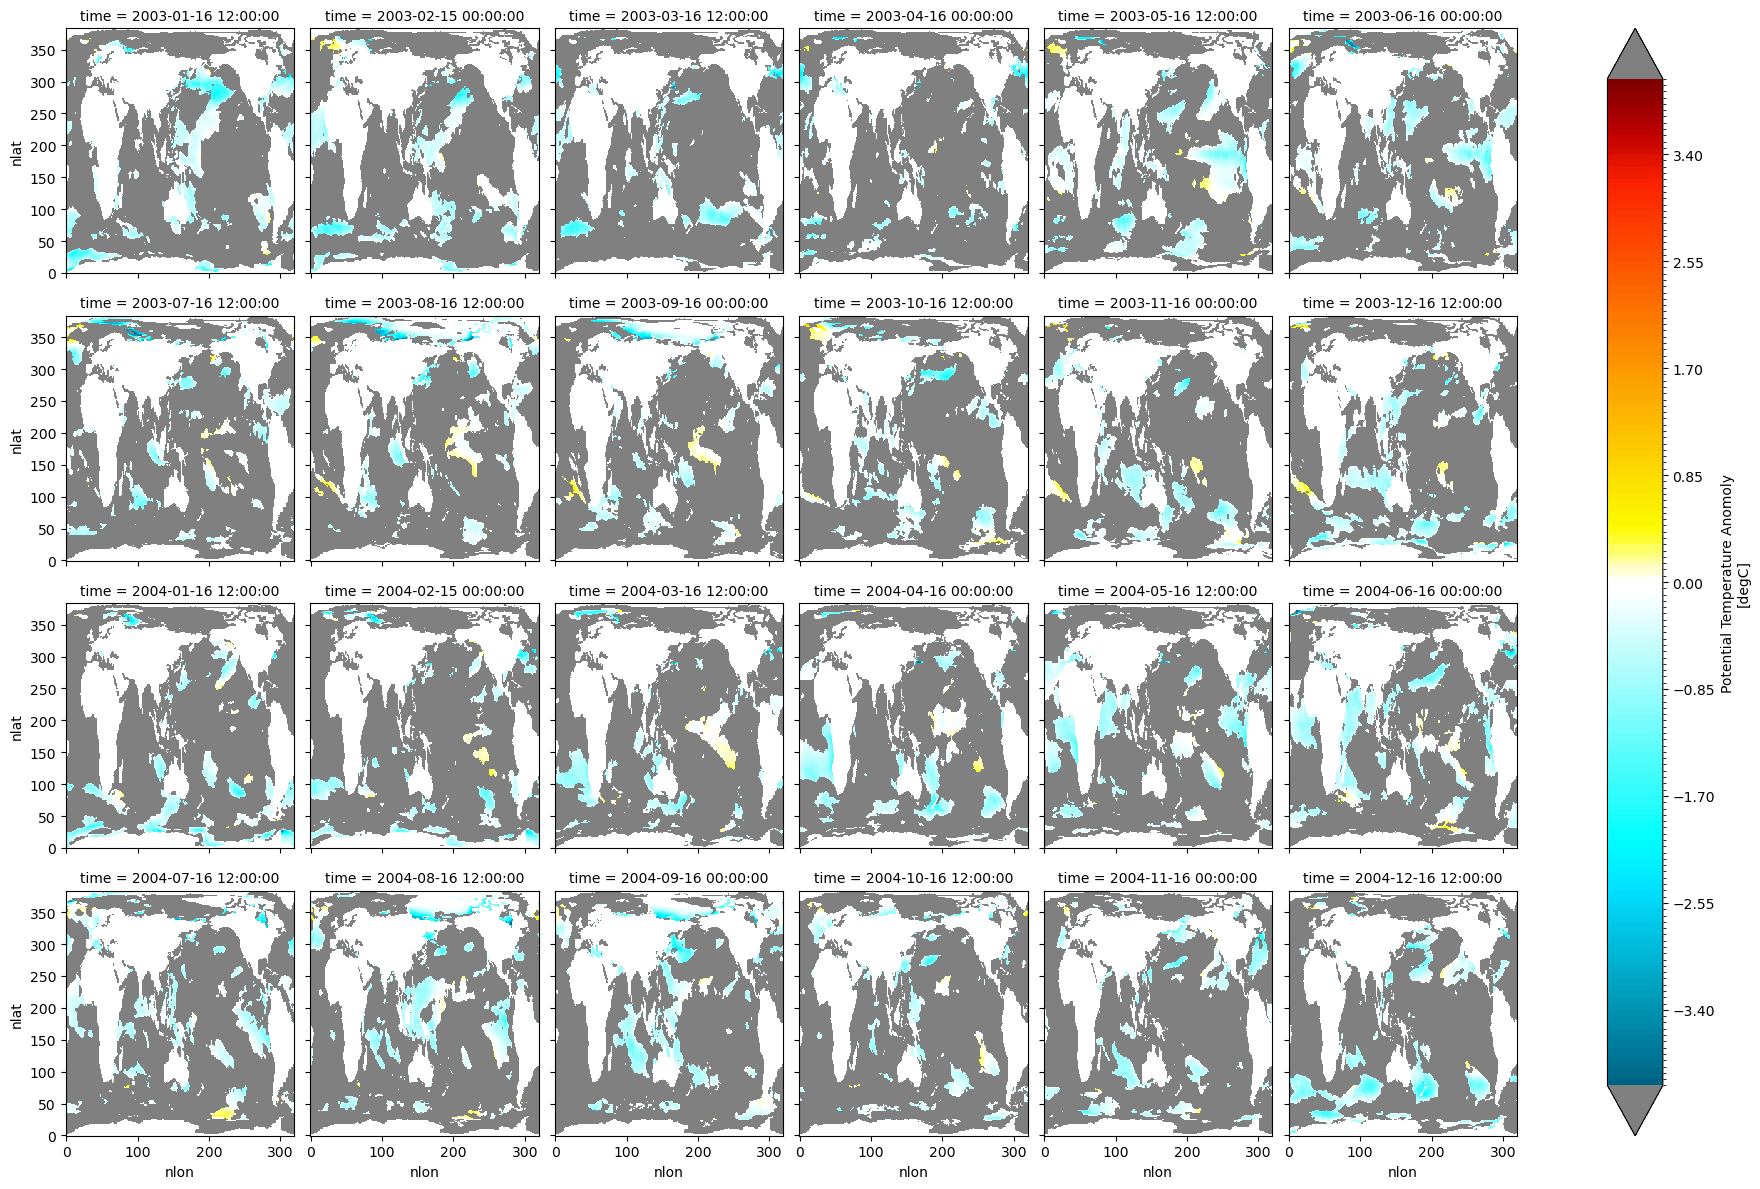

In [37]:
# Marine Coldwaves at Timesteps

ds_fosi.isel(time=slice(0,24)).MCW_annual.plot(col='time', col_wrap=6, cmap=cmap_div, levels=levs, cbar_kwargs={'extend':'both', 'norm':norm})

In [38]:
# Compute Intensity and Merge MHW and MCW together

ds_intensity_ann = xr.merge([ds_fosi.MHW_annual.where(ds_fosi.MHW_annual>-999, drop=False).groupby('time.year').mean('time').rename('MHW_INTENSITY'),ds_fosi.MCW_annual.where(ds_fosi.MCW_annual>-999, drop=False).groupby('time.year').mean('time').rename('MCW_INTENSITY')])

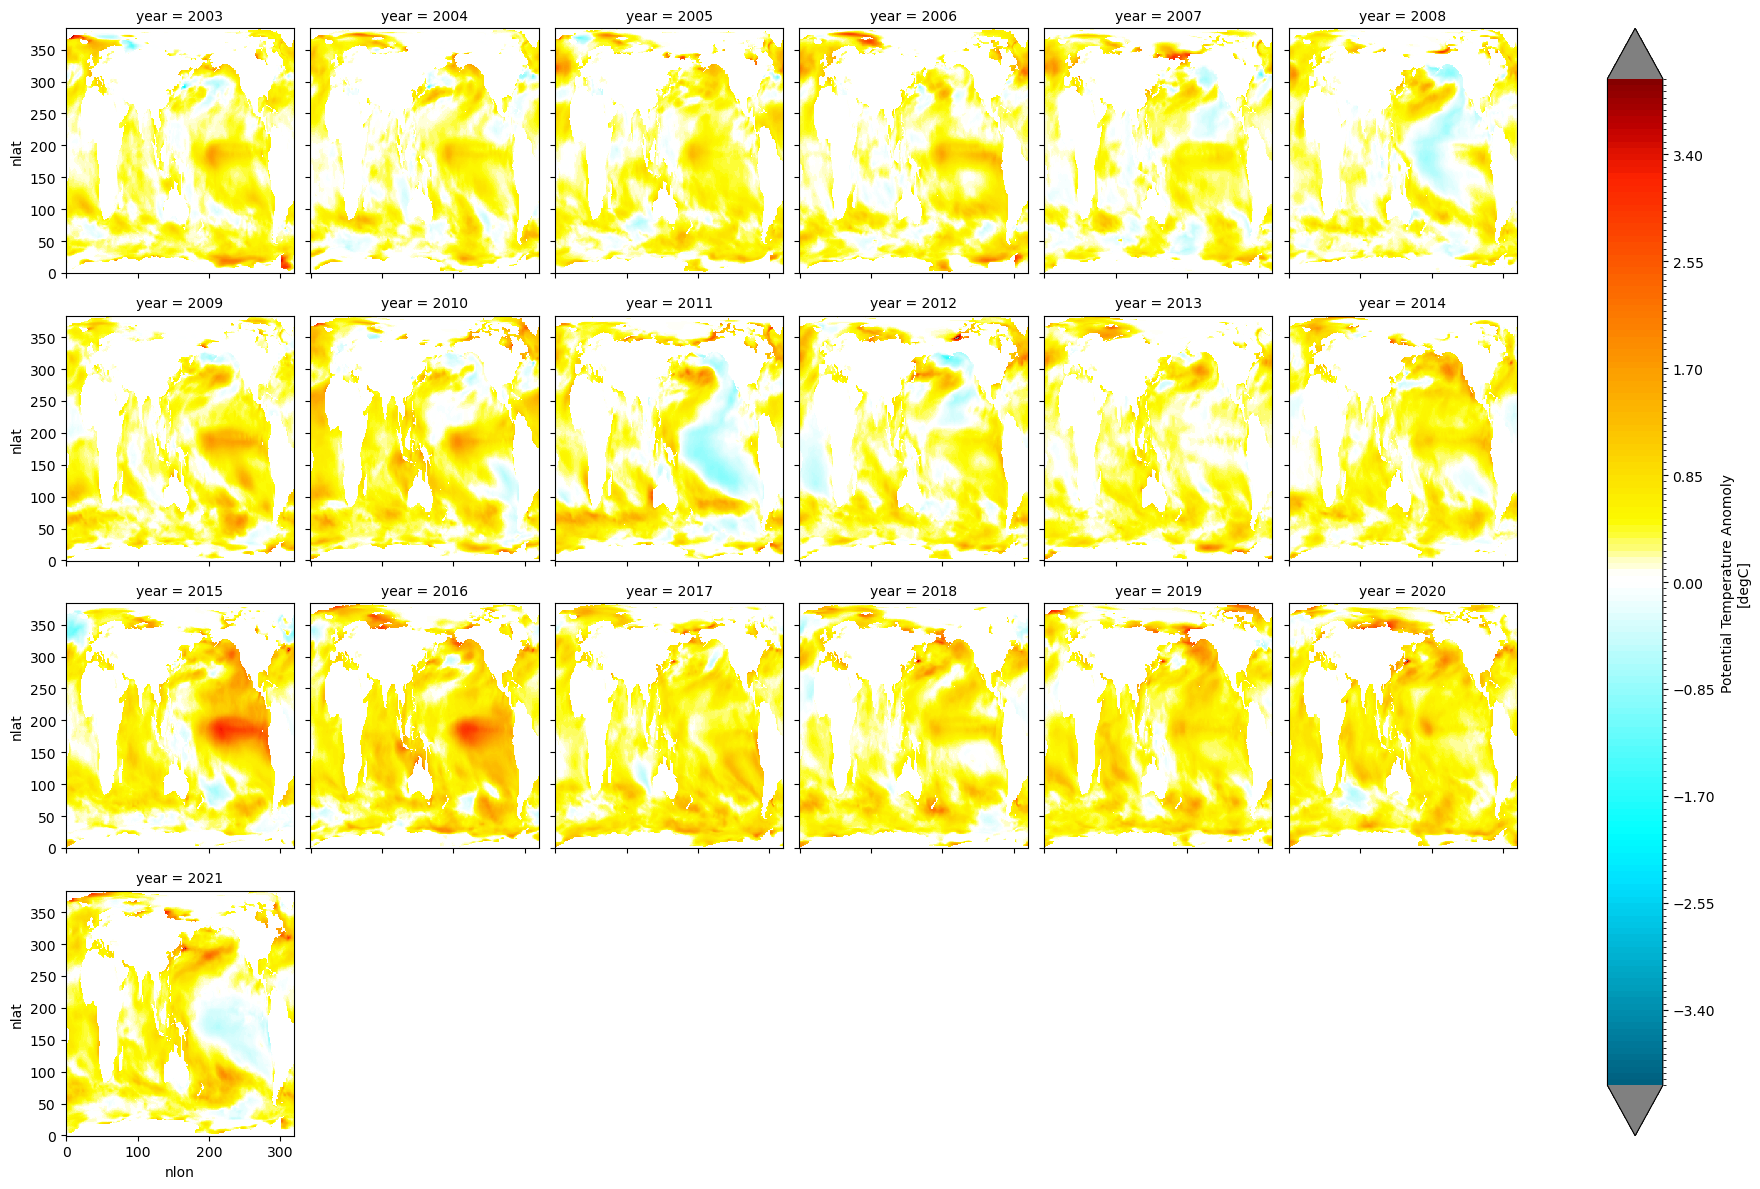

In [43]:
# Intensity of Marine Heatwaves

ds_intensity_ann['MHW_INTENSITY'].plot(col='year',col_wrap=6, cmap=cmap_div, levels=levs, cbar_kwargs={'extend':'both', 'norm':norm})

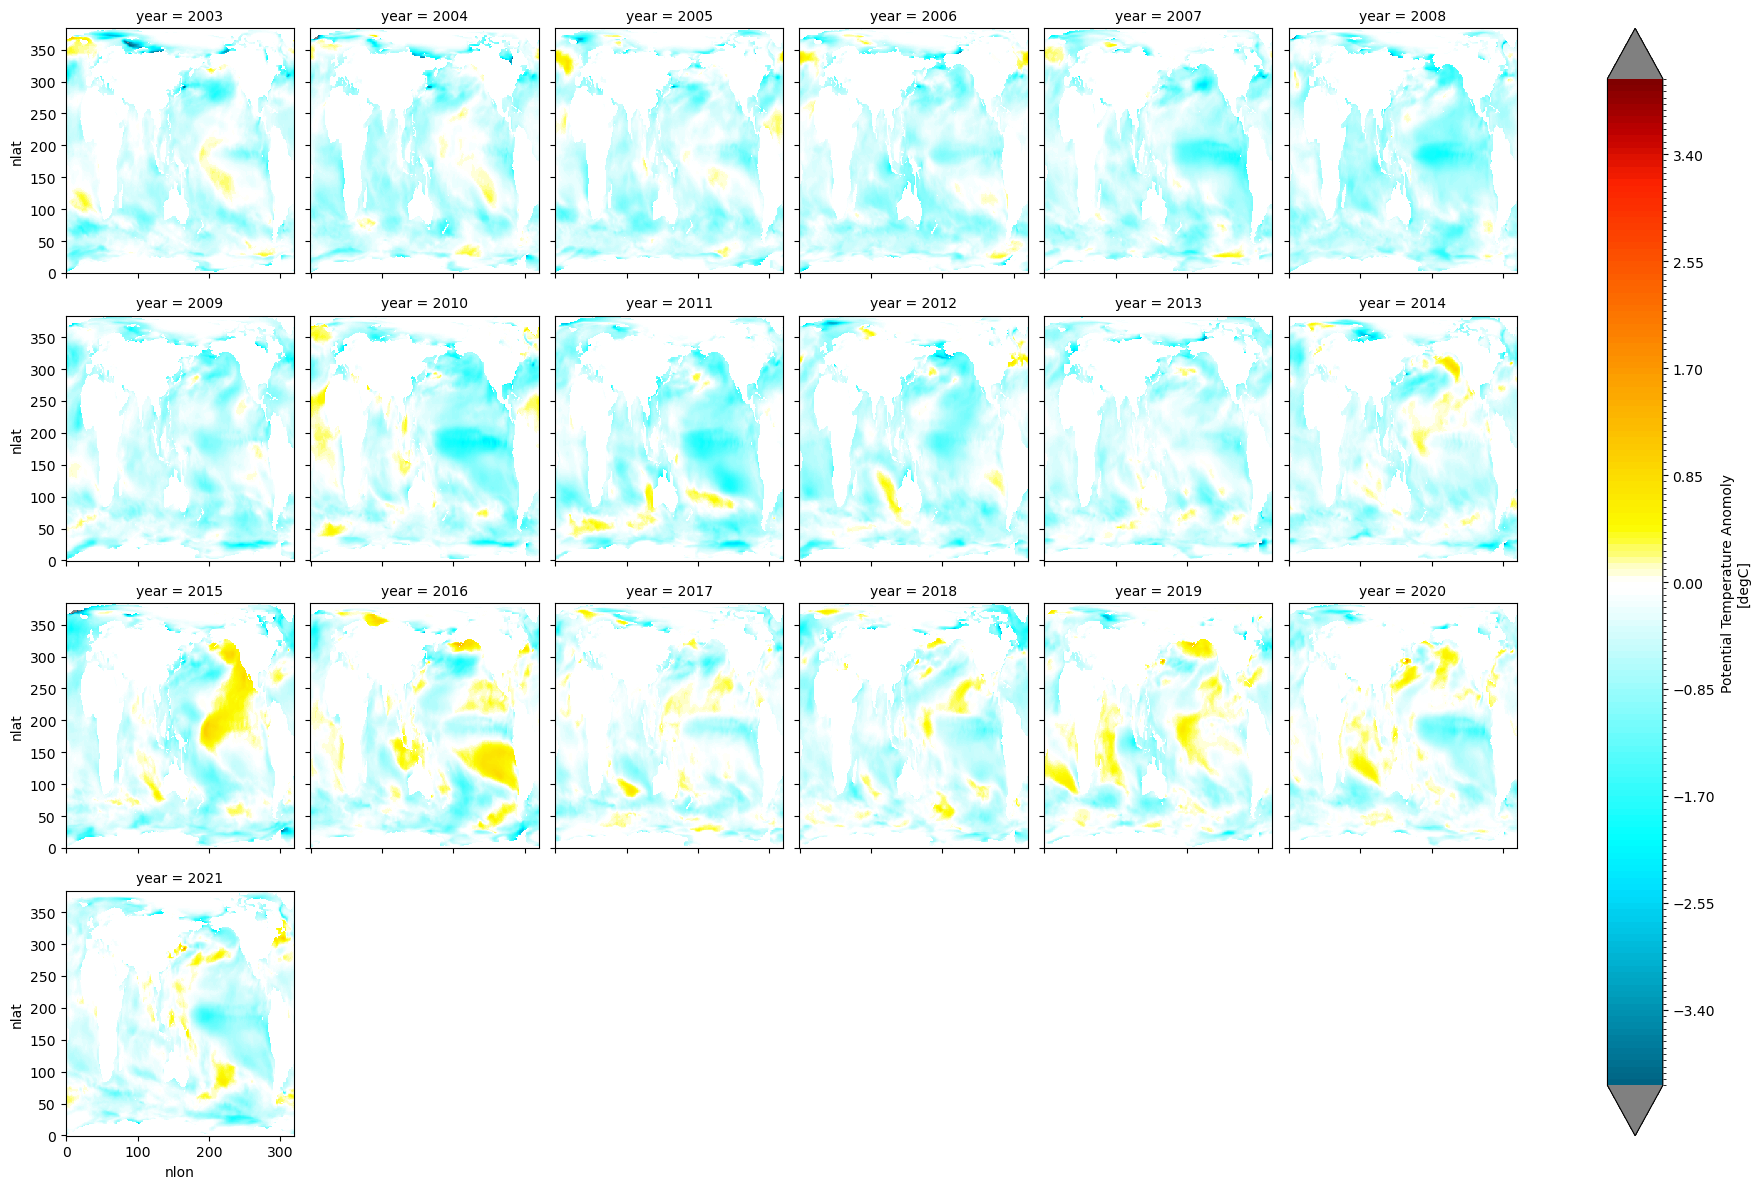

In [40]:
# Intensity of Marine Coldwaves

ds_intensity_ann['MCW_INTENSITY'].plot(col='year',col_wrap=6, cmap=cmap_div, levels=levs, cbar_kwargs={'extend':'both', 'norm':norm})

## Dask Maxxing

In [41]:
# # Frequency of MHW
# ### SINCE THIS IS QUANTILE PER LOCATION IT DOESN'T MAKE SENSE, will always be 2

# def freq_ufunc(arr):
#     not_nan = arr[~np.isnan(arr)]
#     if len(not_nan)!=0:
#         not_nan = not_nan[not_nan!=-9999]
#         freq = len(not_nan)/len(arr)
#     else:
#         freq = np.nan
#     return freq

# def frequency_per_mon(groups):
#     res_list = []
#     var_list = ['MHW', 'MCW']
#     for var in var_list:
#         result = xr.apply_ufunc(freq_ufunc,
#                                 groups[var],
#                                 input_core_dims=[['time']],
#                                 output_core_dims=[[]],
#                                 vectorize=True,
#                                 dask="parallelized",
#                                 on_missing_core_dim='copy'
#                                 )
#         result = result.rename(var+'_FREQ')
#         result.attrs = {'long_name': 'Frequency of Marine Heatwave/Coldwave Events, normalized by time', 'units': ''}
#         res_list.append(result)
#     out = xr.merge(res_list)
#     return out

# # Apply the custom function using groupby and map
# ds_frequency = ds_fosi.groupby("time.month").map(frequency_per_mon)#.plot(levels=np.arange(0, 1.1, .1), col='month', col_wrap=3)

In [42]:
# ### Intensity of MHW's

# def intense_ufunc(ex_arr):#, t_arr):
#     not_nan = ex_arr[~np.isnan(ex_arr)]
#     if len(not_nan)!=0:
#         # not_nan = not_nan[not_nan>-999]
#         intense = (np.mean(ex_arr))# - np.mean(t_arr)) / np.std(t_arr)  #zscore of average mhw/mcw
#     else:
#         intense = np.nan
#     return intense

# def intensity_per_mon(group):
#     res_list = []
#     var_list = ['MHW', 'MCW']
#     for var in var_list:
#         print(group[var].where(group[var]>-999, drop=True))
#         result = xr.apply_ufunc(intense_ufunc,
#                                 group[var].where(group[var]>-999, drop=False),
#                                 # groups['TEMP'],
#                                 input_core_dims=[['time']],#,['time']],
#                                 output_core_dims=[[]],
#                                 vectorize=True,
#                                 # dask="parallelized",
#                                 on_missing_core_dim='copy'
#                                 )
#         result = result.rename(var+'_INTE')
#         result.attrs = {'long_name': 'Intensity of Marine Heatwave Events, normalized by time', 'units': ''}
#         res_list.append(result)
#     out = xr.merge(res_list)
#     return out

# # Apply the custom function using groupby and map
# ds_intensity = ds_fosi.groupby("time.month").map(intensity_per_mon)

# ds_intensity.MCW_INTE.plot(levels=np.arange(-999, 1.1, .1), col='month', col_wrap=3)